# Neutrinos en términos qg (§151, §152, §154, §156)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Viny2030/qang/blob/main/notebooks/qang_neutrinos_es.ipynb)

Un neutrino se produce y se detecta en un estado de sabor (e, μ, τ) pero viaja como superposición de estados de masa: la oscilación de sabor es una rotación de un sistema de dos o tres niveles, justo lo que describe la lectura qg de qang. Este notebook corre los cuatro estudios de neutrinos de RESEARCH_NOTES en **simuladores locales de dispositivos IBM** (backends `Fake*` con ruido calibrado; sin cuenta y sin hardware), comparando siempre la lectura **sin qang** (disparos crudos) y **con qang** (el filtro qg: conservar los disparos del sector de peso de Hamming conservado, más corrección de lectura).

| § | tema | resultado publicado |
|---|---|---|
| 151 | oscilaciones en vacío; tres sabores en tres qubits | qg_Z = cos²2θ + sin²2θ cos Δ; en el máximo el ángulo de mezcla es un cuarto del ángulo qang; filtro 3.4× |
| 152 | a través de la Tierra: materia (MSW) | la materia imita violación CP (A_CP = 0.042 con δ_CP = 0); filtro 2.8× |
| 154 | oscilaciones colectivas en un gas denso de neutrinos | lo que se conserva es el número de ν₂ (base de masa), no el número de sabor; ahí el filtro da 2.2–2.8× |
| 156 | neutrinos solares: la conversión MSW adiabática | P_ee baja de 0.54 a 0.30; todo el Sol es una sola rotación |

Qué es la relación y qué no: es modelado. La oscilación es una rotación y qang la lee con barras de error conocidas; no elimina la trigonometría en general y no es una aceleración cuántica. Las corridas publicadas usaron 3 backends y más disparos; acá 2 backends y menos disparos (unos 5 minutos en total en una CPU de laptop).

## 1. Instalación

In [1]:
import importlib, subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "qang", "qiskit-aer", "qiskit-ibm-runtime", "matplotlib"], check=False)
importlib.invalidate_caches()
try:
    from qang import neutrino
    ok = all(hasattr(neutrino, f) for f in ("collective_trotter_circuit", "solar_circuit"))
except ImportError:
    ok = False
if not ok:  # the published qang predates §154/§156: install from GitHub
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--force-reinstall", "--no-deps",
                    "git+https://github.com/Viny2030/qang.git"], check=True)
    print("installed qang from GitHub; if an import fails below, restart the runtime once")
import qang
print("qang", qang.__version__)

qang 0.10.0


## 2. Configuración común

In [2]:
import math, time
import numpy as np
import matplotlib.pyplot as plt
import qiskit_ibm_runtime.fake_provider as fp
from qiskit import transpile
from qiskit.quantum_info import Statevector
from qang import ibm
from qang import neutrino as nu

BACKENDS = ("FakeBrisbane", "FakeTorino")   # ECR and CZ native gates
FR = "filtered_readout"
T0 = time.time()


def sampler(backend):
    try:
        from qiskit_ibm_runtime.executor_sampler import Sampler
    except ImportError:
        from qiskit_ibm_runtime import SamplerV2 as Sampler
    return Sampler(mode=backend)


def run(circuits, b, weight, shots):
    ts = [transpile(qc, b, optimization_level=1, seed_transpiler=137) for qc in circuits]
    res = sampler(b).run(ts, shots=shots).result()
    return [ibm.ibm_qg(r, t, b, weight=weight) for r, t in zip(res, ts)]

## 3. Oscilaciones en vacío (§151)

**Dos sabores en un qubit.** Pasar a la base de masa, dejar que los estados de masa acumulen la fase Δ = Δm² L / 2E y volver da

qg_Z = 1 − 2 P(e→μ) = cos²(2θ) + sin²(2θ) cos Δ,

la ley de cosenos esférica: el vector de Bloch precesa sobre un cono de semiángulo 2θ y el ángulo qang arccos(qg_Z) es la distancia recorrida. En el máximo de oscilación (Δ = π) vale exactamente 4θ, así que θ = arccos(qg_Z)/4 hereda el ruido de disparo independiente de θ, 1/(4√(N + 1/2)), de §125. Fuera del máximo la relación no es lineal: qg elimina el sin² solo en el máximo.

In [3]:
rng = np.random.default_rng(151)
N_SHOTS = 1000
print(f"theta   mean of theta_hat   std   (theory {nu.mixing_angle_std(N_SHOTS):.4f})")
for th in (0.1, 0.3, 0.5, 0.7):
    k = rng.binomial(N_SHOTS, nu.two_flavour_probability(th, math.pi), 2000)
    est = np.array([nu.mixing_angle_from_maximum(1 - 2 * x / N_SHOTS) for x in k])
    print(f"{th:4.1f}    {est.mean():.4f}              {est.std(ddof=1):.4f}")

theta   mean of theta_hat   std   (theory 0.0079)
 0.1    0.0999              0.0079
 0.3    0.2999              0.0077
 0.5    0.5000              0.0078
 0.7    0.7006              0.0080


**Tres sabores en tres qubits**, una excitación: qubit k excitado = sabor k (e, μ, τ). La matriz PMNS son tres rotaciones RBS y dos compuertas de fase; la propagación, una compuerta de fase por qubit; todas conservan el peso y el filtro se aplica. Un haz de ν_μ a 1300 km (línea de base tipo DUNE), δ_CP = −π/2. Publicado: |P̂ − P| medio crudo / filtro + lectura 0.048 / 0.013 (Brisbane), 0.034 / 0.010 (Torino); la asimetría CP A_CP = P(ν_μ→ν_e) − P(ν̄_μ→ν̄_e) a 2.6 GeV (exacta 0.025) sobrevive incluso sin filtro, porque es una diferencia de dos circuitos casi idénticos.

exact P(mu -> e, mu, tau) at 2.6 GeV: [0.063 0.013 0.924]
exact A_CP at 2.6 GeV: 0.0250


FakeBrisbane: mean |P_hat - P| raw 0.046, filtered+readout 0.011 (gain 4.4x); A_CP raw 0.0157, filtered+readout 0.0247


FakeTorino: mean |P_hat - P| raw 0.034, filtered+readout 0.011 (gain 3.0x); A_CP raw 0.0239, filtered+readout 0.0212


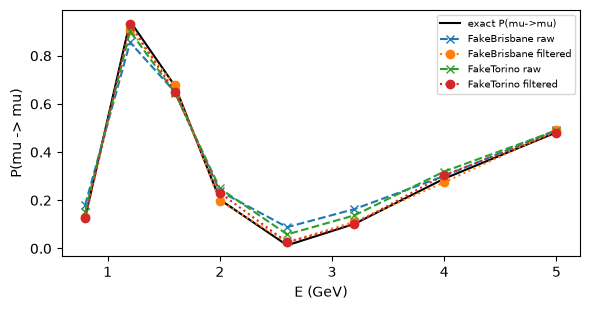

In [4]:
L, DCP = 1300.0, -math.pi / 2
ENERGIES = (0.8, 1.2, 1.6, 2.0, 2.6, 3.2, 4.0, 5.0)
exact = np.array([nu.three_flavour_probabilities(L, E, DCP)[1] for E in ENERGIES])
print("exact P(mu -> e, mu, tau) at 2.6 GeV:", np.round(nu.three_flavour_probabilities(L, 2.6, DCP)[1], 3))
print(f"exact A_CP at 2.6 GeV: {nu.cp_asymmetry(L, 2.6, DCP):.4f}")
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(ENERGIES, exact[:, 1], "k-", label="exact P(mu->mu)")
for name in BACKENDS:
    b = getattr(fp, name)()
    outs = run([nu.three_flavour_circuit("mu", L, E, DCP) for E in ENERGIES], b, 1, 2000)
    err = {k: np.abs(np.array([ibm.occupations(o, k) for o in outs]) - exact).mean() for k in ("raw", FR)}
    oc = run([nu.three_flavour_circuit("mu", L, 2.6, DCP, anti) for anti in (False, True)], b, 1, 10000)
    acp = {k: ibm.occupations(oc[0], k)[0] - ibm.occupations(oc[1], k)[0] for k in ("raw", FR)}
    print(f"{name}: mean |P_hat - P| raw {err['raw']:.3f}, filtered+readout {err[FR]:.3f} "
          f"(gain {err['raw'] / err[FR]:.1f}x); A_CP raw {acp['raw']:.4f}, filtered+readout {acp[FR]:.4f}")
    ax.plot(ENERGIES, [ibm.occupations(o, "raw")[1] for o in outs], "x--", label=f"{name} raw")
    ax.plot(ENERGIES, [ibm.occupations(o, FR)[1] for o in outs], "o:", label=f"{name} filtered")
ax.set_xlabel("E (GeV)"); ax.set_ylabel("P(mu -> mu)"); ax.legend(fontsize=7); plt.tight_layout(); plt.show()

## 4. A través de la Tierra: materia (§152)

Los electrones de la Tierra suman A = 2√2 G_F N_e E a la entrada ν_e del Hamiltoniano (−A para antineutrinos). El circuito alterna el paso exacto de vacío con una compuerta de fase en el qubit ν_e (Trotter de segundo orden), así que todas las compuertas siguen conservando el peso. Publicado: **la materia sola imita violación CP**, A_CP = 0.042 con δ_CP = 0, mayor que la señal CP de vacío (0.025), y el circuito filtrado la ve (0.029–0.035; el resto de la diferencia es error de Trotter con r = 2).

In [5]:
RHO, R = 2.85, 2
acp_exact = nu.cp_asymmetry(L, 2.6, 0.0, rho=RHO)
sv = lambda anti: np.abs(Statevector(nu.matter_trotter_circuit("mu", L, 2.6, 0.0, RHO, R, antineutrino=anti, measure=False)).data[1]) ** 2
print(f"A_CP at delta_CP = 0: exact {acp_exact:.4f}, noiseless Trotter r = {R}: {sv(False) - sv(True):.4f}")
for name in BACKENDS:
    b = getattr(fp, name)()
    oc = run([nu.matter_trotter_circuit("mu", L, 2.6, 0.0, RHO, R, antineutrino=anti) for anti in (False, True)], b, 1, 10000)
    acp = {k: ibm.occupations(oc[0], k)[0] - ibm.occupations(oc[1], k)[0] for k in ("raw", FR)}
    print(f"{name}: matter-only A_CP raw {acp['raw']:.4f}, filtered+readout {acp[FR]:.4f}")

A_CP at delta_CP = 0: exact 0.0422, noiseless Trotter r = 2: 0.0333


FakeBrisbane: matter-only A_CP raw 0.0273, filtered+readout 0.0307


FakeTorino: matter-only A_CP raw 0.0279, filtered+readout 0.0298


## 5. Oscilaciones colectivas en un gas denso de neutrinos (§154)

En una supernova la densidad de neutrinos es tan alta que oscilan juntos: H = Σ ω_i B·σ_i/2 + (μ/2N) Σ σ_i·σ_j. El término σ_i·σ_j conserva el número de excitaciones en cualquier base, pero el término de vacío es diagonal solo en la base de **masa**, así que lo conservado es el número de ν₂, no el número total de sabor. Abajo: N = 4 neutrinos que empiezan en un estado de masa con dos ν₂ (peso 2), circuito de Trotter en la base de masa, comparado con el circuito sin ruido (el preregistro publicado comparaba con la evolución exacta y falló por error de Trotter; esta es la comparación post hoc, 2.2–2.8× publicado).

In [6]:
OMEGAS, MU, THETA, DT = (0.25, 0.5, 0.75, 1.0), 4.0, 0.195, 0.5
TIMES = (0.5, 1.0, 1.5, 2.0)
circ = lambda t, m=True: nu.collective_trotter_circuit(OMEGAS, MU, THETA, "0011", t, int(round(t / DT)), "mass", "mass", measure=m)
idx = np.arange(16)
ref = []
for t in TIMES:
    p = Statevector(circ(t, False)).probabilities()
    ref.append([p[(idx >> i) & 1 == 1].sum() for i in range(4)])
ref = np.array(ref)
for name in BACKENDS:
    b = getattr(fp, name)()
    outs = run([circ(t) for t in TIMES], b, 2, 4000)
    err = {k: np.abs(np.array([ibm.occupations(o, k) for o in outs]) - ref).mean() for k in ("raw", FR)}
    print(f"{name}: mean |P(nu_2) error| raw {err['raw']:.3f}, filtered+readout {err[FR]:.3f} "
          f"(gain {err['raw'] / err[FR]:.1f}x), kept {np.mean([o['kept_raw'] for o in outs]):.2f}")

FakeBrisbane: mean |P(nu_2) error| raw 0.056, filtered+readout 0.029 (gain 1.9x), kept 0.64


FakeTorino: mean |P(nu_2) error| raw 0.033, filtered+readout 0.013 (gain 2.5x), kept 0.79


## 6. Neutrinos solares: la conversión MSW adiabática (§156)

La luz producida en el núcleo del Sol tarda más de 100 000 años en llegar a la superficie; los neutrinos lo cruzan en unos dos segundos y nos llegan 8 minutos después, una imagen en vivo del núcleo. Un ν_e nacido ahí encuentra una densidad de electrones que baja de (ρY_e) ≈ 100 g/cm³ a cero. Por encima de unos pocos MeV la densidad del núcleo supera la resonancia MSW, el neutrino sigue adiabáticamente el autoestado de materia más pesado y sale del Sol como ν₂. En el camino a la Tierra los estados de masa pierden su coherencia, así que llega una mezcla de ν₁ y ν₂ y

P_ee = c₁₃⁴ (cos²θ₁₂ p₁ + sin²θ₁₂ p₂) + s₁₃⁴,

**lineal en el qg_Z del qubit ν₂**. `nu.solar_circuit` corta un Sol a escala (perfil exponencial, h = 100 km) en r capas de densidad constante, cada una un propagador exacto 2×2 escrito como RZ·RBS·RZ en dos qubits en el sector de peso 1, y luego rota a la base de masa de vacío: el filtro se aplica. Dos controles: un qubit (sin filtro posible, sin compuertas de dos qubits) y el circuito **compilado**: como solo se observa p₂, todo el Sol es una sola rotación, un único RBS.

Publicado (3 backends, predicciones S1–S6 preregistradas, todas pasaron): en el circuito por capas con r = 8 el filtro reduce el error 1.9–2.3× y la caída MSW filtrada es 0.20–0.22 (exacta 0.231). Pero el circuito compilado de un solo RBS le gana incluso sin filtro (0.005–0.008 contra 0.008–0.015), y un qubit con corrección de lectura es igual de bueno (0.002–0.003): las fases se pierden antes de la detección, así que el observable es una población y la respuesta adiabática es clásica. Una computadora cuántica podría aportar algo solo donde sobrevive la coherencia (regeneración día-noche en la Tierra, efectos colectivos).

exact P_ee       [0.536 0.517 0.478 0.405 0.353 0.305 0.304]
adiabatic P_ee   [0.536 0.517 0.477 0.402 0.354 0.315 0.301]
slab circuit r = 8 (noiseless)  [0.539 0.525 0.489 0.391 0.369 0.297 0.307]


FakeBrisbane
  slab raw                   mean |error| vs noiseless circuit 0.0247   MSW drop 0.177
  slab filtered+readout      mean |error| vs noiseless circuit 0.0114   MSW drop 0.211
  compiled raw               mean |error| vs noiseless circuit 0.0090   MSW drop 0.222
  compiled filtered+readout  mean |error| vs noiseless circuit 0.0019   MSW drop 0.243
  one qubit readout          mean |error| vs noiseless circuit 0.0025   MSW drop 0.238


FakeTorino
  slab raw                   mean |error| vs noiseless circuit 0.0165   MSW drop 0.201
  slab filtered+readout      mean |error| vs noiseless circuit 0.0066   MSW drop 0.223
  compiled raw               mean |error| vs noiseless circuit 0.0060   MSW drop 0.225
  compiled filtered+readout  mean |error| vs noiseless circuit 0.0019   MSW drop 0.240
  one qubit readout          mean |error| vs noiseless circuit 0.0038   MSW drop 0.238


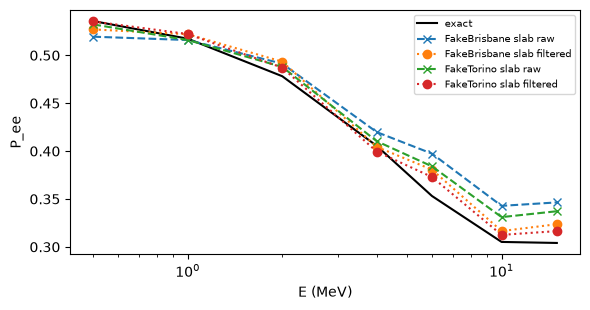

total time 252 s


In [7]:
H, X, RS = 100.0, 800.0, 8
E_SOL = (0.0005, 0.001, 0.002, 0.004, 0.006, 0.010, 0.015)   # GeV
pee = lambda p2s: np.array([nu.solar_pee_from_p2(float(p)) for p in p2s])
ex = pee([nu.solar_p2_exact(E, H, X) for E in E_SOL])
slab = pee([nu.solar_p2(E, H, X, RS) for E in E_SOL])
print("exact P_ee      ", np.round(ex, 3))
print("adiabatic P_ee  ", np.round([nu.solar_pee_adiabatic(E) for E in E_SOL], 3))
print(f"slab circuit r = {RS} (noiseless) ", np.round(slab, 3))
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.semilogx(np.array(E_SOL) * 1e3, ex, "k-", label="exact")
for name in BACKENDS:
    b = getattr(fp, name)()
    so = run([nu.solar_circuit(E, H, X, RS) for E in E_SOL], b, 1, 4000)
    co = run([nu.solar_circuit(E, H, X, RS, compiled=True) for E in E_SOL], b, 1, 4000)
    qo = run([nu.solar_circuit(E, H, X, RS, encoding="qubit") for E in E_SOL], b, None, 4000)
    est = {"slab raw": pee([ibm.occupations(o, "raw")[1] for o in so]),
           "slab filtered+readout": pee([ibm.occupations(o, FR)[1] for o in so]),
           "compiled raw": pee([ibm.occupations(o, "raw")[1] for o in co]),
           "compiled filtered+readout": pee([ibm.occupations(o, FR)[1] for o in co]),
           "one qubit readout": pee([ibm.occupations(o, "readout")[0] for o in qo])}
    print(name)
    for k, v in est.items():
        print(f"  {k:26s} mean |error| vs noiseless circuit {np.abs(v - slab).mean():.4f}   MSW drop {v[0] - v[5]:.3f}")
    ax.semilogx(np.array(E_SOL) * 1e3, est["slab raw"], "x--", label=f"{name} slab raw")
    ax.semilogx(np.array(E_SOL) * 1e3, est["slab filtered+readout"], "o:", label=f"{name} slab filtered")
ax.set_xlabel("E (MeV)"); ax.set_ylabel("P_ee"); ax.legend(fontsize=7); plt.tight_layout(); plt.show()
print(f"total time {time.time() - T0:.0f} s")

## Resumen

* **Vacío (§151):** la oscilación es una rotación; en el máximo el ángulo de mezcla es un cuarto del ángulo qang, con una barra de error independiente de θ. Tres sabores entran en el sector de peso 1 y el filtro reduce el error unas 3×.
* **Materia (§152):** la Tierra imita una asimetría CP mayor que la propia señal CP; el circuito filtrado la recupera.
* **Colectivas (§154):** lo conservado es el número de ν₂; el filtro funciona en lecturas en base de masa, no en las de sabor.
* **Solares (§156):** la caída MSW adiabática de P_ee se lee con el filtro, pero como las fases se pierden en el camino, el observable es una población: el circuito compilado de una sola rotación le gana a cualquier circuito por capas, y un qubit alcanza para dos sabores.

Detalles completos, predicciones preregistradas y todos los backends: `RESEARCH_NOTES.md` §151–§156 y `examples/neutrino_*_qg.py`. §153 (Λ como tercer filtro en LiH) y §155 (los cuatro números cuánticos) todavía no están en un notebook.